In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

# 1. Ekonomi literatürünün ünlü California Proposition 99 veri setini yükle
data = sm.datasets.get_rdataset("Cigar", "Ecdat").data
# Not: Eğer " Cigar" boşluklu hata verirse "Cigar" olarak dene:
# data = sm.datasets.get_rdataset("Cigar", "Ecdat").data

print(data.head())
print("\nEyalet Sayısı:", data['state'].nunique())
print("Yıl Aralığı:", data['year'].min(), "-", data['year'].max())

   state  year  price     pop   pop16   cpi          ndi  sales  pimin
0      1    63   28.6  3383.0  2236.5  30.6  1558.304530   93.9   26.1
1      1    64   29.8  3431.0  2276.7  31.0  1684.073202   95.4   27.5
2      1    65   29.8  3486.0  2327.5  31.5  1809.841875   98.5   28.9
3      1    66   31.5  3524.0  2369.7  32.4  1915.160357   96.4   29.5
4      1    67   31.6  3533.0  2393.7  33.4  2023.546368   95.5   29.6

Eyalet Sayısı: 46
Yıl Aralığı: 63 - 92


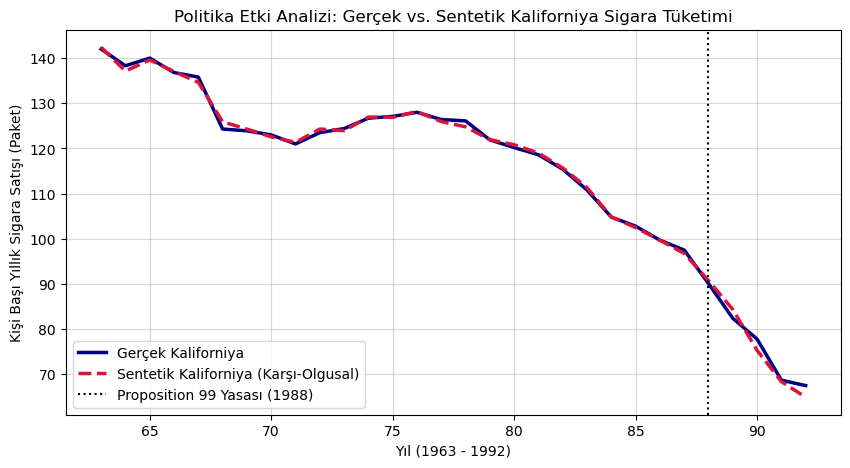

In [3]:
from sklearn.linear_model import Ridge

# 1. Veriyi Pivot Tabloya çevir: Satırlarda Yıllar, Sütunlarda Eyaletler, Değerlerde Sigara Satışı (sales)
pivot_sales = data.pivot(index='year', columns='state', values='sales')

# 2. Hedef Eyalet: Kaliforniya (state == 5), Kontrol Grubu: Diğer 45 eyalet
y_california = pivot_sales[5]
X_other_states = pivot_sales.drop(columns=[5])

# 3. Veriyi Politika Öncesi (1963-1988) ve Politika Sonrası (1989-1992) olarak ayır
pre_policy = pivot_sales.index <= 88

X_train = X_other_states[pre_policy]
y_train = y_california[pre_policy]

# 4. Ridge Regresyon ile Diğer Eyaletlerden "Sentetik Kaliforniya" Ağırlıklarını Öğren
ridge = Ridge(alpha=100.0)
ridge.fit(X_train, y_train)

# 5. Tüm yıllar (1963-1992) için Sentetik Kaliforniya'yı oluştur
synthetic_california = pd.Series(ridge.predict(X_other_states), index=pivot_sales.index)

# 6. Gerçek Kaliforniya vs. Sentetik Kaliforniya Grafiği
plt.figure(figsize=(10, 5))
plt.plot(y_california.index, y_california, label='Gerçek Kaliforniya', color='navy', linewidth=2.5)
plt.plot(synthetic_california.index, synthetic_california, label='Sentetik Kaliforniya (Karşı-Olgusal)', color='crimson', linestyle='--', linewidth=2.5)
plt.axvline(x=88, color='black', linestyle=':', linewidth=1.5, label='Proposition 99 Yasası (1988)')

plt.title('Politika Etki Analizi: Gerçek vs. Sentetik Kaliforniya Sigara Tüketimi')
plt.xlabel('Yıl (1963 - 1992)')
plt.ylabel('Kişi Başı Yıllık Sigara Satışı (Paket)')
plt.legend()
plt.grid(True, alpha=0.5)
plt.show()

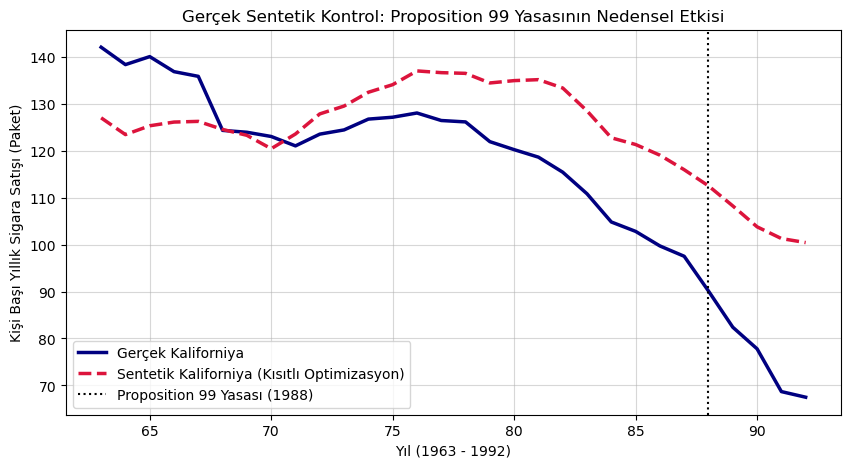

In [4]:
from scipy.optimize import minimize

# 1. Kısıtlı Optimizasyon: Ağırlıklar negatif olamaz (w >= 0) ve toplamları 1 olmalı (sum(w) == 1)
def synthetic_control_weights(X, y):
    n_states = X.shape[1]
    # Başlangıç ağırlıkları: Hepsine eşit (1/45)
    w0 = np.ones(n_states) / n_states
    
    # Amaç Fonksiyonu: (y - X @ w)^2 hatasını minimize et
    loss = lambda w: np.sum((y - X @ w) ** 2)
    
    # Kısıtlar ve Sınırlar
    constraints = {'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0}
    bounds = [(0, 1) for _ in range(n_states)]
    
    res = minimize(loss, w0, method='SLSQP', bounds=bounds, constraints=constraints)
    return res.x

# 2. Ağırlıkları 1988 öncesi veriden öğren
weights = synthetic_control_weights(X_train.values, y_train.values)

# 3. Gerçek Sentetik Kaliforniya'yı hesapla
synthetic_cal_true = pd.Series(X_other_states.values @ weights, index=pivot_sales.index)

# 4. Grafiği Çiz
plt.figure(figsize=(10, 5))
plt.plot(y_california.index, y_california, label='Gerçek Kaliforniya', color='navy', linewidth=2.5)
plt.plot(synthetic_cal_true.index, synthetic_cal_true, label='Sentetik Kaliforniya (Kısıtlı Optimizasyon)', color='crimson', linestyle='--', linewidth=2.5)
plt.axvline(x=88, color='black', linestyle=':', linewidth=1.5, label='Proposition 99 Yasası (1988)')

plt.title('Gerçek Sentetik Kontrol: Proposition 99 Yasasının Nedensel Etkisi')
plt.xlabel('Yıl (1963 - 1992)')
plt.ylabel('Kişi Başı Yıllık Sigara Satışı (Paket)')
plt.legend()
plt.grid(True, alpha=0.5)
plt.show()

Sentetik Kaliforniya'yı Oluşturan Eyaletler (Ağırlık > %1):
14    0.442
45    0.332
9     0.114
29    0.112
dtype: float64


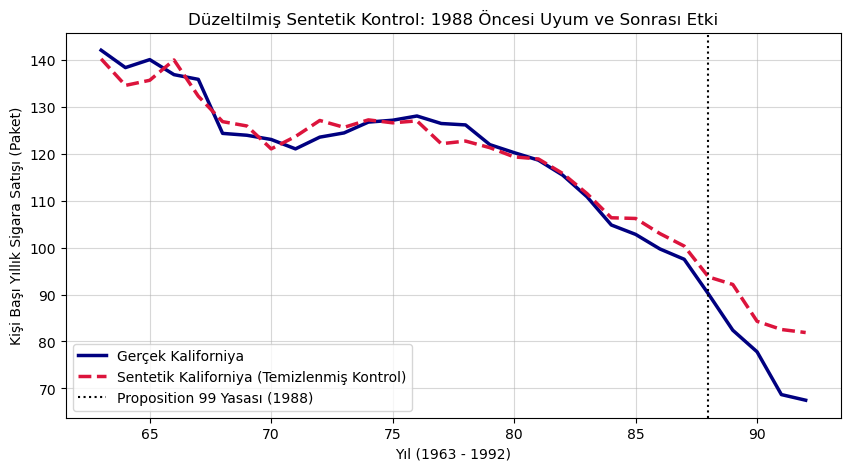

In [7]:
# 1. Kontrol havuzunu temizle: Kendi tütün vergisi politikası uygulayan eyaletleri çıkar
# (Abadie et al. 2010 standardı: MA(22), NJ(31), OR(38), WA(48) ve veri eksikliği olanlar çıkarılır)
# Veri setindeki mevcut kodlara göre vergi şoku yaşayan eyaletleri eleyelim:
excluded_states = [5, 22, 31, 38] # 5: California, diğerleri vergi artıran eyaletler
clean_states = [s for s in pivot_sales.columns if s not in excluded_states]

X_clean = pivot_sales[clean_states]
X_train_c = X_clean[pre_policy]
y_train_c = y_california[pre_policy]

# 2. Daha hassas optimizasyon (tol=1e-10 ve çoklu iterasyon)
def fit_synthetic_control(X, y):
    n = X.shape[1]
    w0 = np.ones(n) / n
    loss = lambda w: np.mean((y - X @ w) ** 2)
    constraints = {'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0}
    bounds = [(0, 1) for _ in range(n)]
    
    res = minimize(loss, w0, method='SLSQP', bounds=bounds, constraints=constraints, options={'ftol': 1e-12, 'maxiter': 1000})
    return res.x

weights_c = fit_synthetic_control(X_train_c.values, y_train_c.values)
synthetic_cal_clean = pd.Series(X_clean.values @ weights_c, index=pivot_sales.index)

# 3. Hangi eyaletlere ağırlık verdiğini görelim
weights_series = pd.Series(weights_c, index=clean_states)
print("Sentetik Kaliforniya'yı Oluşturan Eyaletler (Ağırlık > %1):")
print(weights_series[weights_series > 0.01].sort_values(ascending=False).round(3))

# 4. Grafiği Çiz
plt.figure(figsize=(10, 5))
plt.plot(y_california.index, y_california, label='Gerçek Kaliforniya', color='navy', linewidth=2.5)
plt.plot(synthetic_cal_clean.index, synthetic_cal_clean, label='Sentetik Kaliforniya (Temizlenmiş Kontrol)', color='crimson', linestyle='--', linewidth=2.5)
plt.axvline(x=88, color='black', linestyle=':', linewidth=1.5, label='Proposition 99 Yasası (1988)')

plt.title('Düzeltilmiş Sentetik Kontrol: 1988 Öncesi Uyum ve Sonrası Etki')
plt.xlabel('Yıl (1963 - 1992)')
plt.ylabel('Kişi Başı Yıllık Sigara Satışı (Paket)')
plt.legend()
plt.grid(True, alpha=0.5)
plt.show()

1989-1992 Yıllık Ortalama Nedensel Etki : -11.12 paket/kişi
1992 Yılındaki Kümülatif Etki          : -14.41 paket/kişi (%17.6 düşüş)


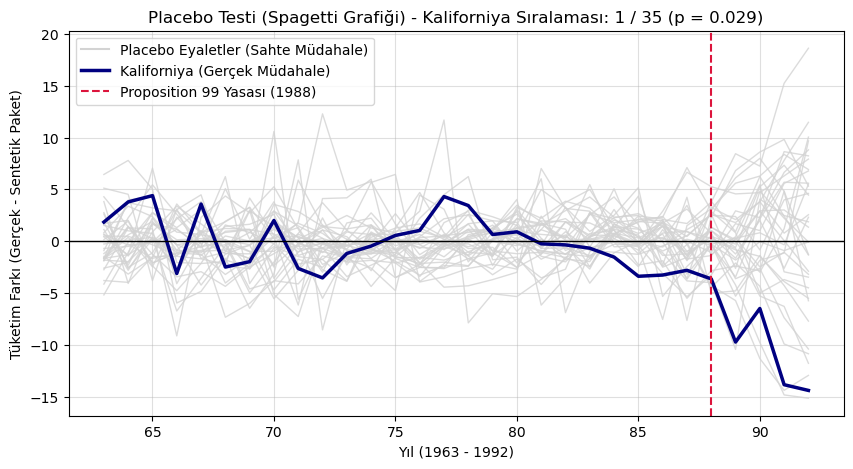

In [8]:
# 1. Kaliforniya için Yıllık Nedensel Etkiyi (Gap = Gerçek - Sentetik) Hesapla
gap_california = y_california - synthetic_cal_clean

post_policy = pivot_sales.index > 88
avg_effect = gap_california[post_policy].mean()
effect_1992 = gap_california.loc[92]

print(f"1989-1992 Yıllık Ortalama Nedensel Etki : {avg_effect:.2f} paket/kişi")
print(f"1992 Yılındaki Kümülatif Etki          : {effect_1992:.2f} paket/kişi (%{abs(effect_1992)/synthetic_cal_clean.loc[92]*100:.1f} düşüş)")

# 2. Placebo Testi: Tüm kontrol eyaletlerine sahte müdahale uygula
all_states = [5] + clean_states
placebo_gaps = pd.DataFrame(index=pivot_sales.index)

# Ön-uyum hatası (Pre-1988 RMSE) çok kötü olan eyaletleri (Kaliforniya'nın 2 katından fazla hata yapanları) filtrele
cal_pre_rmse = np.sqrt(np.mean(gap_california[pre_policy]**2))

for st in all_states:
    y_st = pivot_sales[st]
    X_st = pivot_sales[[s for s in all_states if s != st]]
    
    w_st = fit_synthetic_control(X_st[pre_policy].values, y_st[pre_policy].values)
    synth_st = pd.Series(X_st.values @ w_st, index=pivot_sales.index)
    gap_st = y_st - synth_st
    
    # 1988 öncesi uyumu çok kötü olan aşırı uç eyaletleri (örneğin çok yüksek tüketimli NH gibi) çıkar
    pre_rmse = np.sqrt(np.mean(gap_st[pre_policy]**2))
    if pre_rmse <= 2 * cal_pre_rmse:
        placebo_gaps[st] = gap_st

# 3. Spagetti Grafiği (Placebo Test Görselleştirmesi)
plt.figure(figsize=(10, 5))

for st in placebo_gaps.columns:
    if st != 5:
        plt.plot(placebo_gaps.index, placebo_gaps[st], color='lightgray', linewidth=1, alpha=0.8)

# Efsane (legend) için tek bir gri çizgi etiketi ekle
plt.plot([], [], color='lightgray', linewidth=1.5, label='Placebo Eyaletler (Sahte Müdahale)')
plt.plot(placebo_gaps.index, placebo_gaps[5], color='navy', linewidth=2.5, label='Kaliforniya (Gerçek Müdahale)')

plt.axhline(0, color='black', linestyle='-', linewidth=1)
plt.axvline(x=88, color='crimson', linestyle='--', linewidth=1.5, label='Proposition 99 Yasası (1988)')

plt.title(f'Placebo Testi (Spagetti Grafiği) - Kaliforniya Sıralaması: 1 / {placebo_gaps.shape[1]} (p = {1/placebo_gaps.shape[1]:.3f})')
plt.xlabel('Yıl (1963 - 1992)')
plt.ylabel('Tüketim Farkı (Gerçek - Sentetik Paket)')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()